### What is Lumbar Spinal Stenosis? 

Lumbar spinal stenosis is a medical condition characterized by narrowing of the spinal canal in the lower back (lumbar region, vertebrae L1-L5). This narrowing compresses the spinal cord and nerve roots, leading to pain, numbness, and other symptoms.

### The Significance of the Topic
Early diagnosis and classification of lumbar spinal stenosis depend on medical imaging research since it helps doctors choose the best course of action, so increasing long-term survival rates, preventing irreversible consequences, and improving patient outcomes.

This project focuses on organizing, managing, and analyzing a lumbar spine MRI dataset used for medical image classification. 
The goal is to build a structured and reproducible data pipeline that supports understanding of the dataset and prepares it for future machine learning applications.
The dataset contains MRI images grouped into three diagnostic categories that represent different structural conditions of the lumbar spine:
- Herniated Disc: Lumbar disc herniation causing nerve compression
- Thecal Sac Compression: Narrowing affecting the thecal sac space
- No Stenosis: Normal lumbar spine without stenosis
Each image is associated with metadata such as its label, and a public link to the image file.

Key Features:
- 13,686 preprocessed images ready for training
- 3-class classification: Herniated Disc, Thecal Sac Compression, No Stenosis
- Standardized resolution: 400×400×1 (grayscale)


### Data Source
The data used in this project is obtained from a publicly available dataset hosted on Kaggle titled Diagnosis Lumbar Spinal Patients MRI Dataset. This dataset is a preprocessed and labeled version of lumbar spine MRI images and is derived from the original Lumbar Spine MRI Dataset published on Mendeley Data.

**How the Data Is Collected**  
The original MRI scans were collected in clinical hospital settings from patients experiencing lower back pain. These scans were generated using MRI machines and stored as medical imaging files. The Kaggle dataset is created by selecting clinically relevant MRI slices from the original dataset, converting them into image files, resizing them to a fixed resolution, and assigning diagnostic labels. The final dataset is distributed as image files organized into folders based on class labels.

**Where the Data came from?**  
The raw MRI data was generated by MRI scanners operated by medical professionals as part of routine clinical examinations. The labeled Kaggle dataset was created by researchers and data scientists who processed the original medical images and prepared them for machine learning tasks.

**Known and Expected Limitations** 
The dataset is derived from a larger raw MRI dataset and represents a selected subset of images. While the images are labeled, the labeling process and criteria are dependent on prior preprocessing decisions. Additionally, the dataset is limited to three diagnostic categories and may not capture the full range of lumbar spine conditions. As with most medical imaging datasets, class imbalance and variability in image quality may also be present.

Dataset Link: https://www.kaggle.com/datasets/abdullahkhan70/lumbar-spinal-mri-dataset?select=LumbarSpinalStenosisba22f7680b50f0174004d7e9a2578d1edf1fb24b

Dataset is uploaded on hugging face for easier view.   

Training dataset: https://huggingface.co/datasets/hitikaghanani/project_ds

Test dataset: https://huggingface.co/datasets/hitikaghanani/DS_project_test

### Class Labels:
- Herniated Disc: 
A herniated disc occurs when the soft inner material of an intervertebral disc pushes outward through a tear or weakness in the outer layer. This protrusion can compress nearby spinal nerves or the spinal cord.
Clinical relevance- Can cause pain, numbness, or weakness. Common cause of lower back pain and sciatica
In MRI imaging, visible disc bulge or extrusion beyond normal disc boundary.

- No Stenosis: 
This category represents normal or non-pathological spinal structure, where there is no clinically significant narrowing of the spinal canal or nerve passageways.
Clinical relevance- No compression of nerves or spinal cord. Considered baseline or healthy reference condition
In MRI imaging, normal disc shape and alignment. No visible compression

- Thecal Sac: 
The thecal sac is the protective membrane that surrounds the spinal cord and cerebrospinal fluid. Abnormality in this structure typically indicates compression, deformation, or narrowing of the space containing neural tissue.
Clinical relevance- May indicate spinal canal narrowing. This can result from disc bulging, ligament thickening, or structural degeneration
In MRI imaging, visible compression or distortion of the fluid-filled sac. Possible narrowing of spinal canal



In [1]:
# All imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score
from datasets import load_dataset
import requests
from PIL import Image
from io import BytesIO
import dill
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torchvision import transforms
import os
import ipywidgets as widgets
from IPython.display import display
import plotly.graph_objects as go
import json
from torch.utils.data import DataLoader


# Data Exploration


In [3]:
df= pd.read_csv(r"train.csv")
print("Total records:", len(df))
print("Columns:",df.columns.tolist())
df.head()


Total records: 10948
Columns: ['image_name', 'label', 'image_link']


,image_name,label,image_link
0,image_10059.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
1,image_10060.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
2,image_10061.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
3,image_10062.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
4,image_10063.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...


In [4]:
print("Total records:", len(df))
print("Columns:",df.columns.tolist())
df.head()

Total records: 10948
Columns: ['image_name', 'label', 'image_link']


,image_name,label,image_link
0,image_10059.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
1,image_10060.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
2,image_10061.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
3,image_10062.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
4,image_10063.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...


In [5]:
# Count per label
label_counts = df["label"].value_counts().reset_index()
label_counts.columns = ["label", "count"]

# Total
total_images = label_counts["count"].sum()

# Percentage of Each Label
label_counts["percentage"] = (label_counts["count"] / total_images) * 100

print("\nClass Distribution\n")
print(label_counts.to_string(index=False))

print("\nTotal Images:", total_images)


Class Distribution

         label  count  percentage
    Thecal Sac   4733   43.231640
   No Stenosis   3152   28.790647
Herniated Disc   3063   27.977713

Total Images: 10948


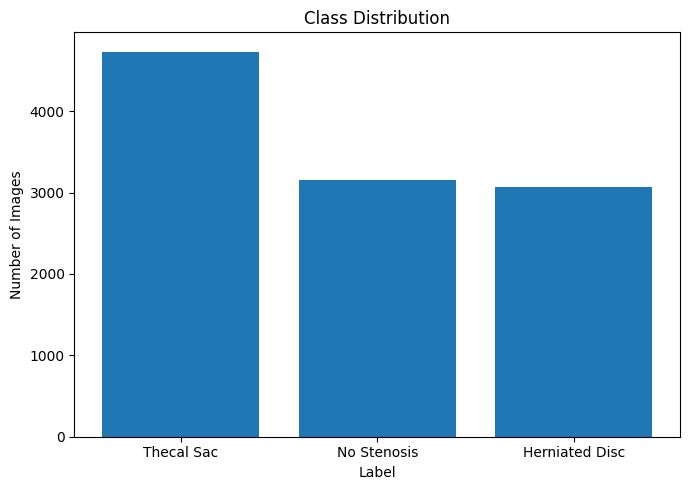

In [6]:
# count labels
label_counts = df["label"].value_counts()

# plot bar chart
plt.figure(figsize=(7,5))
plt.bar(label_counts.index, label_counts.values)

plt.title("Class Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()


- Dataset Summary:
The dataset contains X MRI images distributed across three diagnostic categories and divided into training and test partitions.

- Class Distribution:
The dataset shows (balanced / moderate imbalance / strong imbalance) across diagnostic categories. The Thecal Sac  class contains 43.2%, No Stenosis 28.7%, and Herniated Disc 27.9% of observations.


In [7]:
data = pd.read_csv(r"test.csv")
data

,image_name,label,image_link
0,image_1006.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
1,image_1007.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
2,image_1008.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
3,image_1009.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
4,image_1010.jpg,Herniated Disc,https://huggingface.co/datasets/hitikaghanani/...
...,...,...,...
2733,image_5.jpg,Thecal Sac,https://huggingface.co/datasets/hitikaghanani/...
2734,image_6.jpg,Thecal Sac,https://huggingface.co/datasets/hitikaghanani/...
2735,image_7.jpg,Thecal Sac,https://huggingface.co/datasets/hitikaghanani/...
2736,image_8.jpg,Thecal Sac,https://huggingface.co/datasets/hitikaghanani/...


In [8]:
# Checking for Duplicates

# Full duplicate rows
print("Train full duplicates:", df.duplicated().sum())
print("Test full duplicates:", data.duplicated().sum())

# 2. Duplicate image paths
print("Train duplicate image paths:", df['image_link'].duplicated().sum())
print("Test duplicate image paths:", data['image_link'].duplicated().sum())

Train full duplicates: 0
Test full duplicates: 0
Train duplicate image paths: 0
Test duplicate image paths: 0


In [9]:
# Check for image overlap( To prevent data Leakage)

train_keys = set(df["image_name"] + "|" + df["label"])
test_keys = set(data["image_name"] + "|" + data["label"])

overlap = train_keys.intersection(test_keys)

print("Number of overlapping image_path + label pairs:", len(overlap))

Number of overlapping image_path + label pairs: 652


In [10]:
# Removing duplicates to prevent leakage

# Create temporary key column in train
df["key"] = df["image_name"] + "|" + df["label"]

# Remove overlapping rows
df = df[~df["key"].isin(overlap)]

# Drop temporary column
df = df.drop(columns=["key"])

print("Train size after removing overlap:", len(df))

Train size after removing overlap: 10296


In [12]:
from pathlib import Path
import os

BASE_DIR = Path.cwd()
DATASET_DIR = BASE_DIR / "Dataset" / "LumbarSpinalStenosis" / "LumbarSpinalStenosis"

# Store relative paths
df["image_path"] = df.apply(
    lambda row: str(Path("train") / row["label"] / row["image_name"]),
    axis=1
)

data["image_path"] = data.apply(
    lambda row: str(Path("test") / row["label"] / row["image_name"]),
    axis=1
)

# Validate by resolving relative path against dataset root
df = df[df["image_path"].apply(lambda p: (DATASET_DIR / p).exists())]
data = data[data["image_path"].apply(lambda p: (DATASET_DIR / p).exists())]

Due to class imbalance, we are merging both the datasets and splitting it again into train, validation and test.

In [13]:
full_df = pd.concat([df, data], ignore_index=True)
print("Full dataset size:", len(full_df))
print(full_df["label"].value_counts())

Full dataset size: 13034
label
Thecal Sac        4733
No Stenosis       4300
Herniated Disc    4001
Name: count, dtype: int64


In [14]:
# Train+Val vs Test
trainval_df, new_test_df = train_test_split(
    full_df,
    test_size=0.2,              
    stratify=full_df["label"],
    random_state=42
)

# Train vs Val from trainval
new_train_df, new_val_df = train_test_split(
    trainval_df,
    test_size=0.125,            
    stratify=trainval_df["label"],
    random_state=42
)

print("New train size:", len(new_train_df))
print("New val size:", len(new_val_df))
print("New test size:", len(new_test_df))

print("\nTrain label distribution:")
print(new_train_df["label"].value_counts(normalize=True))

print("\nVal label distribution:")
print(new_val_df["label"].value_counts(normalize=True))

print("\nTest label distribution:")
print(new_test_df["label"].value_counts(normalize=True))

New train size: 9123
New val size: 1304
New test size: 2607

Train label distribution:
label
Thecal Sac        0.363038
No Stenosis       0.329935
Herniated Disc    0.307026
Name: proportion, dtype: float64

Val label distribution:
label
Thecal Sac        0.363497
No Stenosis       0.329755
Herniated Disc    0.306748
Name: proportion, dtype: float64

Test label distribution:
label
Thecal Sac        0.363253
No Stenosis       0.329881
Herniated Disc    0.306866
Name: proportion, dtype: float64


In [15]:
new_train_df.to_csv("train_split.csv", index=False)
new_val_df.to_csv("val_split.csv", index=False)
new_test_df.to_csv("test_split.csv", index=False)

## Next Steps :

 - Apply data augmentation to the training images to improve generalization and reduce overfitting (e.g., small rotations, slight zoom, brightness variation, and controlled noise).
 
 - Selecimport dill
print(dill.__version__)t a baseline deep learning architecture with transfer learning (such as CNN, ResNet, DenseNet, or EfficientNet) and adapt the final layer for the three MRI classes:
 1. No stenosis
 2. Thecal sac compression
 3. Herniated disc

 - Set up the training configuration, including loss function, optimizer, learning rate, batch size, number of epochs, and regularization strategies like early stopping or learning rate scheduling.

 - Train the baseline model while monitoring training and validation performance to identify overfitting or underfitting.

 - Evaluate performance on the validation set using clinically meaningful metrics:
  1. Accuracy
  2. Precision (per class)
  3. Recall (per class)
  4. Macro F1 score
  5. Confusion matrix

 - Run experiments with multiple model architectures under consistent training conditions to enable fair comparison.

 - Select the best-performing model based on balanced performance across classes, with particular attention to accurate detection of pathological cases.

 - Retrain the selected model using combined training and validation data for final learning.

 - Conduct final evaluation on the test set to obtain unbiased performance metrics.

 - Perform error analysis by reviewing misclassified MRI images to understand model weaknesses and identify improvement opportunities.

 - Save the final trained model, along with preprocessing steps and class mappings, for future inference or deployment.


### Data Transformation

In [17]:
# Transformations to prevent overfitting
# Training set Transformation
train_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomRotation(10),
    transforms.RandomResizedCrop(400, scale=(0.9,1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])


In [18]:
# Validation set no transformation
val_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

In [19]:
label_map = {
    "Herniated Disc": 0,
    "No Stenosis": 1,
    "Thecal Sac": 2
}

import json
with open("label_map.json", "w") as f:
    json.dump(label_map, f)

In [24]:
#loads MRI images and their labels from a dataframe
class MRIDataset(Dataset):
    def __init__(self, df, root_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.root_dir = Path(root_dir)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # image_path column now holds a relative path like "train/label/img.jpg"
        img_path = self.root_dir / row["image_path"]
        image = Image.open(img_path).convert("L")

        label = label_map[row["label"]]

        if self.transform:
            image = self.transform(image)

        return image, label

In [25]:
from pathlib import Path

BASE_DIR = Path.cwd()
DATASET_DIR = BASE_DIR / "Dataset" / "LumbarSpinalStenosis" / "LumbarSpinalStenosis"

train_dataset_new = MRIDataset(new_train_df, root_dir=DATASET_DIR, transform=train_transforms)
val_dataset_new   = MRIDataset(new_val_df,   root_dir=DATASET_DIR, transform=val_transforms)
test_dataset_new  = MRIDataset(new_test_df,  root_dir=DATASET_DIR, transform=val_transforms)

train_loader_new = DataLoader(train_dataset_new, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader_new   = DataLoader(val_dataset_new,   batch_size=32, num_workers=2, pin_memory=True)
test_loader_new  = DataLoader(test_dataset_new,  batch_size=32, num_workers=2, pin_memory=True)


In [26]:
images, labels = next(iter(train_loader_new))

print(images.shape)
print(labels.shape)

torch.Size([32, 1, 400, 400])
torch.Size([32])


In [27]:
print("Training set class distribution:")
print(new_train_df["label"].value_counts())
print("Train images:", len(new_train_df))


print("\nValidation set class distribution:")
print(new_val_df["label"].value_counts())
print("Validation images:", len(new_val_df))


Training set class distribution:
label
Thecal Sac        3312
No Stenosis       3010
Herniated Disc    2801
Name: count, dtype: int64
Train images: 9123

Validation set class distribution:
label
Thecal Sac        474
No Stenosis       430
Herniated Disc    400
Name: count, dtype: int64
Validation images: 1304


In [28]:
print("Test images:", len(new_test_df))

Test images: 2607


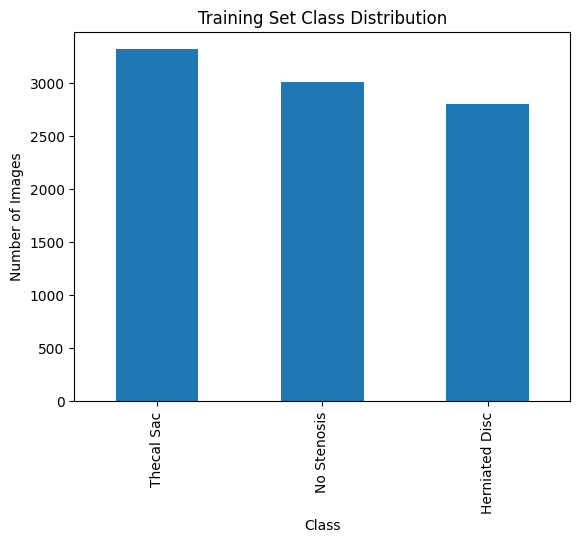

In [29]:
new_train_df["label"].value_counts().plot(kind="bar")

plt.title("Training Set Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

In [30]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [31]:
class_counts = new_train_df["label"].value_counts()
total = class_counts.sum()

weights = torch.tensor([
    total / class_counts["Herniated Disc"],
    total / class_counts["No Stenosis"],
    total / class_counts["Thecal Sac"]
], dtype=torch.float).to(device)


In [32]:
## Weighted cross-entropy loss to mitigate class imbalance
criterion = torch.nn.CrossEntropyLoss(weight=weights)

### Model Training and Evaluation

In [33]:
results = {}

In [34]:
# For all models
def train_model(model, train_loader, val_loader, criterion, optimizer, device, epochs=15):
    train_losses = []
    val_accuracies = []

    best_state = None
    best_val_acc = 0.0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)
        
        
        # validation
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, preds = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (preds == labels).sum().item()

        val_acc = 100 * correct / total
        val_accuracies.append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = model.state_dict()

        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Acc: {val_acc:.2f}%")

    if best_state is not None:
        model.load_state_dict(best_state)

    return train_losses, val_accuracies

In [35]:
BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 3e-4  

In [36]:
class_names = ["Herniated Disc", "No Stenosis", "Thecal Sac"]

def evaluate_model(model, loader, device, title_prefix=""):
    model.eval()
    all_labels, all_preds = [], []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())

    # Metrics
    acc = (np.array(all_labels) == np.array(all_preds)).mean() * 100
    bal_acc = balanced_accuracy_score(all_labels, all_preds) * 100
    print(f"{title_prefix} Accuracy: {acc:.2f}%")
    print(f"{title_prefix} Balanced Accuracy: {bal_acc:.2f}%\n")
    print(f"{title_prefix} Classification Report:\n")
    print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"{title_prefix} Confusion Matrix")
    plt.tight_layout()
    plt.show()

### CNN Model

In [37]:
class SimpleCNN(nn.Module):

    def __init__(self):
        super(SimpleCNN, self).__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2,2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2,2)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2,2)
        )

        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2,2)
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1,1))

        self.fc1 = nn.Linear(256, 128)
        self.fc2 = nn.Linear(128, 3)

        self.dropout = nn.Dropout(0.4)  

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)

        x = self.global_pool(x)
        x = torch.flatten(x, 1)

        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

In [38]:
model = SimpleCNN().to(device)

In [39]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [41]:
cnn_train_losses, cnn_val_accs = train_model(
    model, train_loader_new, val_loader_new,
    criterion, optimizer, device,
    epochs=EPOCHS
)

Epoch 1/15 | Train Loss: 1.0901 | Val Acc: 39.03%
Epoch 2/15 | Train Loss: 1.0841 | Val Acc: 41.49%
Epoch 3/15 | Train Loss: 1.0796 | Val Acc: 43.87%
Epoch 4/15 | Train Loss: 1.0784 | Val Acc: 40.03%
Epoch 5/15 | Train Loss: 1.0756 | Val Acc: 42.10%
Epoch 6/15 | Train Loss: 1.0694 | Val Acc: 37.65%
Epoch 7/15 | Train Loss: 1.0699 | Val Acc: 42.10%
Epoch 8/15 | Train Loss: 1.0662 | Val Acc: 43.40%
Epoch 9/15 | Train Loss: 1.0620 | Val Acc: 43.63%
Epoch 10/15 | Train Loss: 1.0618 | Val Acc: 43.87%
Epoch 11/15 | Train Loss: 1.0606 | Val Acc: 44.63%
Epoch 12/15 | Train Loss: 1.0579 | Val Acc: 41.33%
Epoch 13/15 | Train Loss: 1.0548 | Val Acc: 43.56%
Epoch 14/15 | Train Loss: 1.0548 | Val Acc: 41.10%
Epoch 15/15 | Train Loss: 1.0513 | Val Acc: 41.33%


In [42]:
results["CNN"] = max(cnn_val_accs)

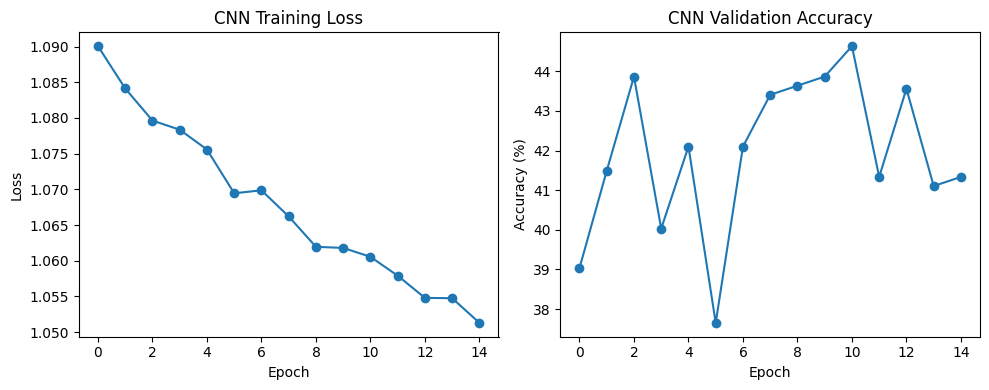

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(cnn_train_losses, marker='o')
plt.title("CNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1,2,2)
plt.plot(cnn_val_accs, marker='o')
plt.title("CNN Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.tight_layout()
plt.show()

=== CNN on Validation Set ===
CNN (Val) Accuracy: 41.33%
CNN (Val) Balanced Accuracy: 38.54%

CNN (Val) Classification Report:

                precision    recall  f1-score   support

Herniated Disc      0.429     0.030     0.056       400
   No Stenosis      0.632     0.156     0.250       430
    Thecal Sac      0.393     0.970     0.560       474

      accuracy                          0.413      1304
     macro avg      0.485     0.385     0.289      1304
  weighted avg      0.483     0.413     0.303      1304



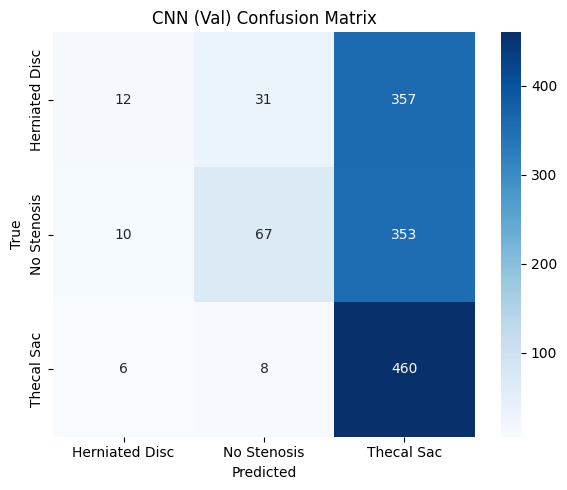

In [44]:
print("=== CNN on Validation Set ===")
evaluate_model(model, val_loader_new, device, title_prefix="CNN (Val)")

In [45]:
# Resnet

In [40]:
import torchvision.models as models
import torch.nn as nn

def build_resnet18(num_classes=3):
    # Load pretrained ResNet18
    resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    
    old_conv = resnet.conv1  # original 3-channel conv

    new_conv = nn.Conv2d(
        in_channels=1,
        out_channels=old_conv.out_channels,
        kernel_size=old_conv.kernel_size,
        stride=old_conv.stride,
        padding=old_conv.padding,
        bias=False
    )

    with torch.no_grad():
        new_conv.weight = nn.Parameter(old_conv.weight.mean(dim=1, keepdim=True))

    resnet.conv1 = new_conv

    in_features = resnet.fc.in_features
    resnet.fc = nn.Linear(in_features, num_classes)

    return resnet

In [47]:
resnet_model = build_resnet18(num_classes=3).to(device)
criterion_resnet = nn.CrossEntropyLoss(weight=weights)
optimizer_resnet = torch.optim.Adam(resnet_model.parameters(), lr=1e-5)

resnet_train_losses, resnet_val_accs = train_model(
    resnet_model, train_loader_new, val_loader_new,
    criterion_resnet, optimizer_resnet,
    device, epochs=EPOCHS
)

Epoch 1/15 | Train Loss: 1.0603 | Val Acc: 47.47%
Epoch 2/15 | Train Loss: 1.0019 | Val Acc: 50.69%
Epoch 3/15 | Train Loss: 0.9463 | Val Acc: 55.52%
Epoch 4/15 | Train Loss: 0.8891 | Val Acc: 59.20%
Epoch 5/15 | Train Loss: 0.8232 | Val Acc: 61.20%
Epoch 6/15 | Train Loss: 0.7699 | Val Acc: 62.96%
Epoch 7/15 | Train Loss: 0.7110 | Val Acc: 65.49%
Epoch 8/15 | Train Loss: 0.6529 | Val Acc: 68.17%
Epoch 9/15 | Train Loss: 0.5969 | Val Acc: 70.48%
Epoch 10/15 | Train Loss: 0.5470 | Val Acc: 71.63%
Epoch 11/15 | Train Loss: 0.4946 | Val Acc: 73.62%
Epoch 12/15 | Train Loss: 0.4482 | Val Acc: 74.62%
Epoch 13/15 | Train Loss: 0.3908 | Val Acc: 77.84%
Epoch 14/15 | Train Loss: 0.3536 | Val Acc: 77.99%
Epoch 15/15 | Train Loss: 0.3166 | Val Acc: 78.99%


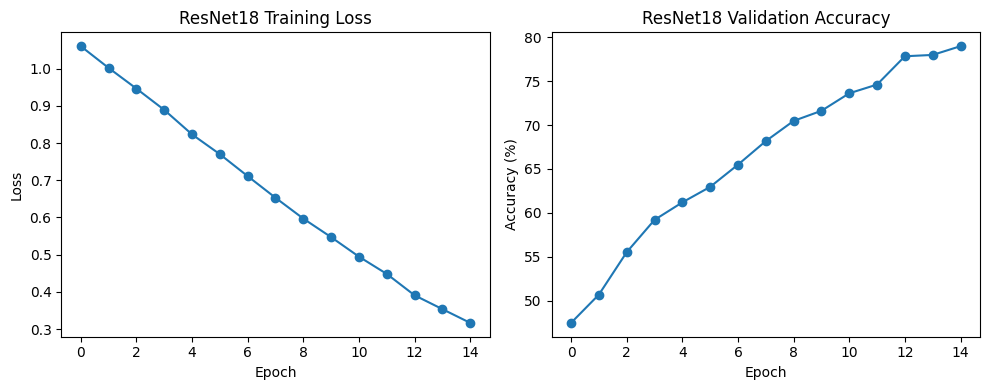

In [48]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(resnet_train_losses, marker='o')
plt.title("ResNet18 Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1,2,2)
plt.plot(resnet_val_accs, marker='o')
plt.title("ResNet18 Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.tight_layout()
plt.show()

=== ResNet18 on Validation Set ===
ResNet18 (Val) Accuracy: 78.99%
ResNet18 (Val) Balanced Accuracy: 79.18%

ResNet18 (Val) Classification Report:

                precision    recall  f1-score   support

Herniated Disc      0.762     0.815     0.787       400
   No Stenosis      0.800     0.809     0.805       430
    Thecal Sac      0.807     0.751     0.778       474

      accuracy                          0.790      1304
     macro avg      0.790     0.792     0.790      1304
  weighted avg      0.791     0.790     0.790      1304



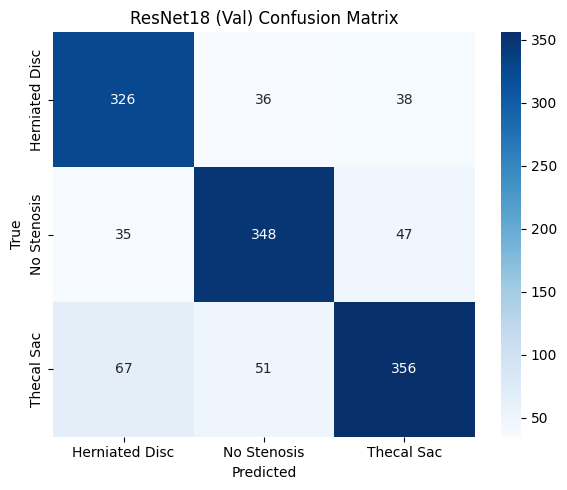

In [49]:
print("=== ResNet18 on Validation Set ===")
evaluate_model(resnet_model, val_loader_new, device, title_prefix="ResNet18 (Val)")

In [50]:
results["ResNet"] = max(resnet_val_accs)

In [51]:
# EfficientNet‑B0 for 1‑channel, 3‑class

In [41]:
from torchvision import models
import torch.nn as nn
import torch

def build_efficientnet_b0(num_classes=3):
    effnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

    # Get original first conv layer
    first_conv = effnet.features[0][0]

    new_conv = nn.Conv2d(
        in_channels=1,
        out_channels=first_conv.out_channels,
        kernel_size=first_conv.kernel_size,
        stride=first_conv.stride,
        padding=first_conv.padding,
        bias=False
    )

    # Initialize weights by averaging over RGB channels
    with torch.no_grad():
        new_conv.weight = nn.Parameter(first_conv.weight.mean(dim=1, keepdim=True))

    # Replace in the model
    effnet.features[0][0] = new_conv

    # Replace classifier head for 3 classes
    in_features = effnet.classifier[1].in_features
    effnet.classifier[1] = nn.Linear(in_features, num_classes)

    return effnet

In [53]:
effnet_model = build_efficientnet_b0(num_classes=3).to(device)
criterion_eff = nn.CrossEntropyLoss(weight=weights) 
optimizer_eff = torch.optim.Adam(effnet_model.parameters(), lr=1e-4)

eff_train_losses, eff_val_accs = train_model(
    effnet_model, train_loader_new, val_loader_new,
    criterion_eff, optimizer_eff, device, epochs=EPOCHS
)

Epoch 1/15 | Train Loss: 1.0446 | Val Acc: 53.45%
Epoch 2/15 | Train Loss: 0.9081 | Val Acc: 61.81%
Epoch 3/15 | Train Loss: 0.7646 | Val Acc: 68.87%
Epoch 4/15 | Train Loss: 0.6480 | Val Acc: 71.86%
Epoch 5/15 | Train Loss: 0.5267 | Val Acc: 77.15%
Epoch 6/15 | Train Loss: 0.4283 | Val Acc: 77.30%
Epoch 7/15 | Train Loss: 0.3422 | Val Acc: 83.05%
Epoch 8/15 | Train Loss: 0.2864 | Val Acc: 84.82%
Epoch 9/15 | Train Loss: 0.2529 | Val Acc: 85.43%
Epoch 10/15 | Train Loss: 0.2168 | Val Acc: 86.73%
Epoch 11/15 | Train Loss: 0.1934 | Val Acc: 85.74%
Epoch 12/15 | Train Loss: 0.1657 | Val Acc: 88.34%
Epoch 13/15 | Train Loss: 0.1613 | Val Acc: 88.50%
Epoch 14/15 | Train Loss: 0.1420 | Val Acc: 90.18%
Epoch 15/15 | Train Loss: 0.1189 | Val Acc: 89.26%


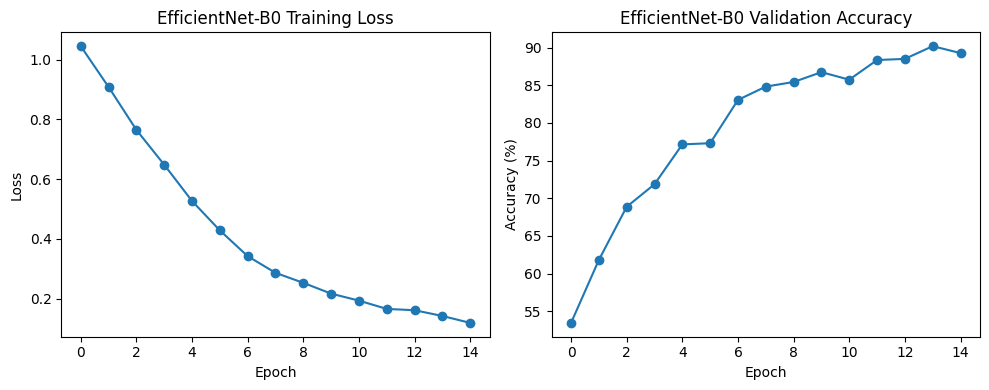

In [54]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(eff_train_losses, marker='o')
plt.title("EfficientNet-B0 Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1,2,2)
plt.plot(eff_val_accs, marker='o')
plt.title("EfficientNet-B0 Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.tight_layout()
plt.show()

=== EfficientNet-B0 on Validation Set ===
EfficientNet-B0 (Val) Accuracy: 89.26%
EfficientNet-B0 (Val) Balanced Accuracy: 89.58%

EfficientNet-B0 (Val) Classification Report:

                precision    recall  f1-score   support

Herniated Disc      0.829     0.955     0.887       400
   No Stenosis      0.916     0.891     0.903       430
    Thecal Sac      0.939     0.842     0.888       474

      accuracy                          0.893      1304
     macro avg      0.895     0.896     0.893      1304
  weighted avg      0.898     0.893     0.893      1304



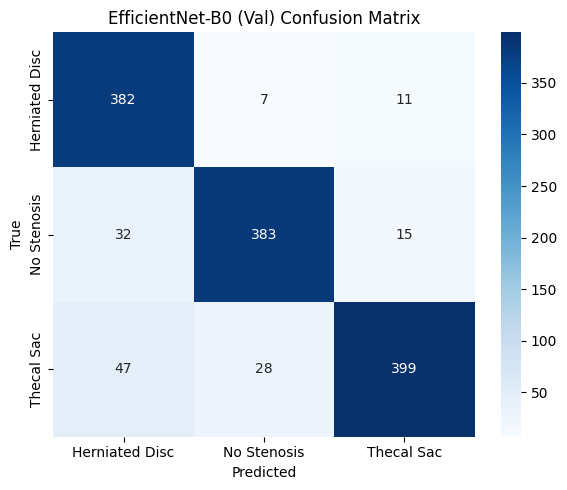

In [55]:
print("=== EfficientNet-B0 on Validation Set ===")
evaluate_model(effnet_model, val_loader_new, device, title_prefix="EfficientNet-B0 (Val)")

In [56]:
results["EfficientNet"] = max(eff_val_accs)

In [57]:
best_model_name = max(results, key=results.get)
print("Best model:", best_model_name)

Best model: EfficientNet


In [58]:
if best_model_name == "CNN":
    best_model = model
elif best_model_name == "ResNet":
    best_model = resnet_model
else:
    best_model = effnet_model

In [59]:
os.makedirs("saved_models", exist_ok=True)

torch.save(model.state_dict(), "saved_models/cnn.pth")
torch.save(resnet_model.state_dict(), "saved_models/resnet.pth")
torch.save(effnet_model.state_dict(), "saved_models/efficientnet.pth")

In [60]:
torch.save(best_model.state_dict(), "saved_models/best_model.pth")

CNN Validation
 Accuracy: 41.33%
 Balanced Accuracy: 38.54%

 Classification Report:

                precision    recall  f1-score   support

Herniated Disc      0.429     0.030     0.056       400
   No Stenosis      0.632     0.156     0.250       430
    Thecal Sac      0.393     0.970     0.560       474

      accuracy                          0.413      1304
     macro avg      0.485     0.385     0.289      1304
  weighted avg      0.483     0.413     0.303      1304



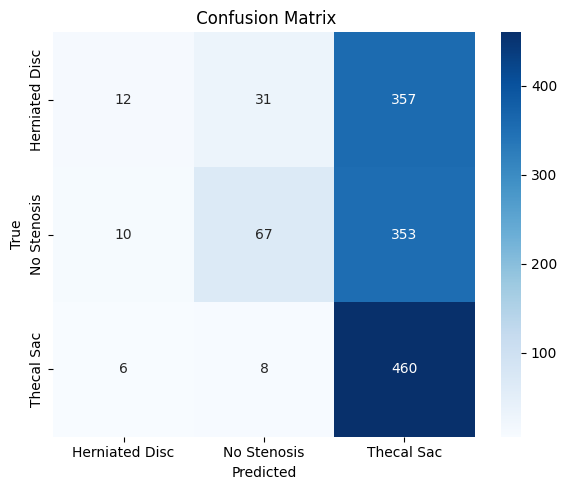

ResNet Validation
 Accuracy: 78.99%
 Balanced Accuracy: 79.18%

 Classification Report:

                precision    recall  f1-score   support

Herniated Disc      0.762     0.815     0.787       400
   No Stenosis      0.800     0.809     0.805       430
    Thecal Sac      0.807     0.751     0.778       474

      accuracy                          0.790      1304
     macro avg      0.790     0.792     0.790      1304
  weighted avg      0.791     0.790     0.790      1304



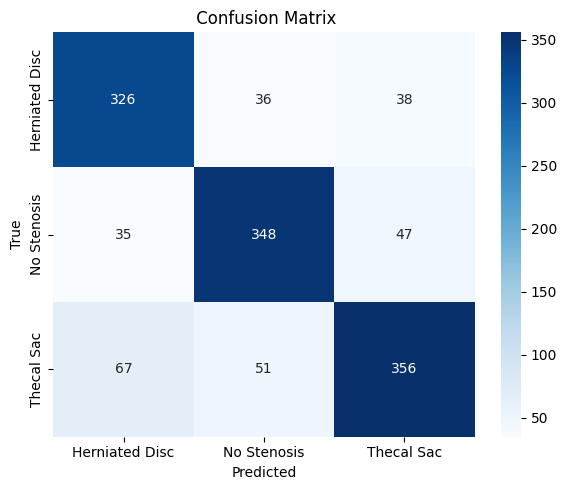

EfficientNet Validation
 Accuracy: 89.26%
 Balanced Accuracy: 89.58%

 Classification Report:

                precision    recall  f1-score   support

Herniated Disc      0.829     0.955     0.887       400
   No Stenosis      0.916     0.891     0.903       430
    Thecal Sac      0.939     0.842     0.888       474

      accuracy                          0.893      1304
     macro avg      0.895     0.896     0.893      1304
  weighted avg      0.898     0.893     0.893      1304



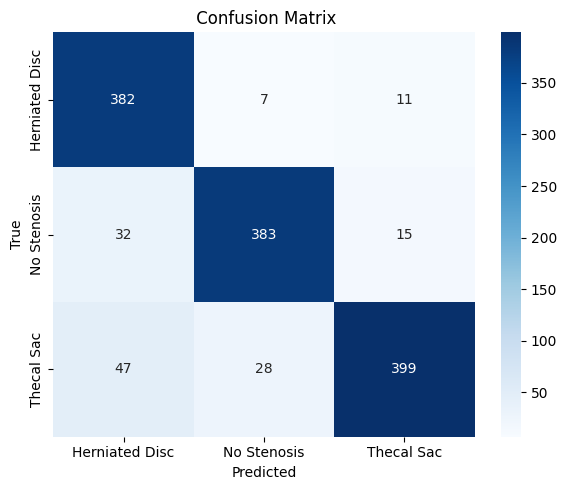

In [63]:
print("CNN Validation")
evaluate_model(model, val_loader_new, device)

print("ResNet Validation")
evaluate_model(resnet_model, val_loader_new, device)

print("EfficientNet Validation")
evaluate_model(effnet_model, val_loader_new, device)


Model Comparison (Validation Accuracy):
CNN: 44.63%
ResNet: 78.99%
EfficientNet: 90.18%

Best Model Selected: EfficientNet

Final Validation Performance of Best Model:
 Accuracy: 89.26%
 Balanced Accuracy: 89.58%

 Classification Report:

                precision    recall  f1-score   support

Herniated Disc      0.829     0.955     0.887       400
   No Stenosis      0.916     0.891     0.903       430
    Thecal Sac      0.939     0.842     0.888       474

      accuracy                          0.893      1304
     macro avg      0.895     0.896     0.893      1304
  weighted avg      0.898     0.893     0.893      1304



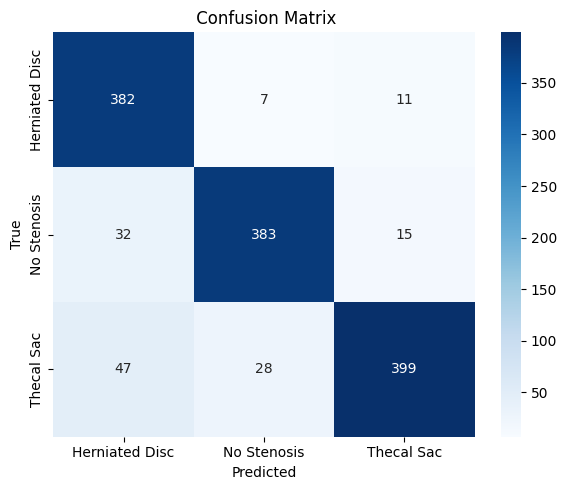

In [64]:
print("\nModel Comparison (Validation Accuracy):")
for k, v in results.items():
    print(f"{k}: {v:.2f}%")

print("\nBest Model Selected:", best_model_name)

print("\nFinal Validation Performance of Best Model:")
evaluate_model(best_model, val_loader_new, device)